# 03 · The Journeyman — Word and Character n-gram TF-IDF (Improvement 1)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Cecile1015/emotion-mirror-cbs4702/blob/main/notebooks/03_improved_classical.ipynb)

Improvement 1 keeps the classifier of the reference baseline (`tfidf_lr`, multinomial logistic regression) and enriches the **representation** with three changes, each motivated by a weakness found in `01_eda` and `02_baselines`:

| Component | Change | Motivation | Lecture |
|---|---|---|---|
| Word bigrams | word n-grams (1, 2) instead of unigrams | a bag of unigrams cannot represent local word order, e.g. *not happy* (the weight of *not* in BoW + LR is at most 0.24) | L6 n-grams |
| Character n-grams | `char_wb` n-grams of length 2–5, joined with the word features in a `FeatureUnion` | 31% of validation/test texts contain a word never seen in training; their unigram features are dropped | L6 FastText subword information |
| Class weights | `class_weight="balanced"` in the cross-entropy loss | imbalance ratio 9.4; *love* and *surprise* have the lowest F1 | L5 loss function |

The model with all three components is called the **full model** (`ngram_lr`). Its hyper-parameters are tuned on the validation split with `PredefinedSplit`. Each component is then removed **one at a time** (three controlled ablations), and every comparison is tested for significance with McNemar's test and the paired bootstrap from `src/evaluate.py`. Because the components may interact, the ablation is run as a complete $2^3$ factorial design on the validation split, and the configuration with the highest validation macro-F1 becomes the selected Improvement 1 model (`improved_lr`).

| Model id | Word n-grams | Char n-grams | Class weights | Role |
|---|---|---|---|---|
| `ngram_lr` | (1, 2) | (2, 5) | balanced | full model |
| `ngram_lr_no_char` | (1, 2) | — | balanced | ablation: character n-grams |
| `ngram_lr_no_cw` | (1, 2) | (2, 5) | — | ablation: class weights |
| `ngram_lr_no_bigram` | (1, 1) | (2, 5) | balanced | ablation: word bigrams |
| `improved_lr` | selected on validation | | | selected Improvement 1 model |
| `ngram_cnb` | (1, 2) | (2, 5) | — | Complement Naive Bayes on the full feature set (extra row) |

**Experimental protocol** (unchanged from `02_baselines`): models are fitted on the 16,000 training texts; every choice is made by **macro-F1 on the validation split**; the test split is used only for the final evaluation and the significance tests. Logistic regression uses `lbfgs` with `tol=1e-6`, as in all notebooks. Random seed: 42.

| § | Content |
|---|---|
| 1 | Data and diagnostic slices |
| 2 | Representations: character n-grams, word bigrams, class weights |
| 3 | Hyper-parameter search with `PredefinedSplit` |
| 4 | Ablation study on the validation split ($2^3$ design) |
| 5 | Final training, test evaluation and saved models |
| 6 | Results: summary tables, significance tests, per-class effects, probability quality |
| 7 | Where does each component matter? Unseen words, negation, misspellings |
| 8 | Discussion |

In [1]:
# Environment setup: runs locally (from the project root or notebooks/) and on Google Colab.
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/Cecile1015/emotion-mirror-cbs4702.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # Colab already provides every package this notebook needs; only the repository is cloned.
    ROOT = Path("/content/emotion-mirror-cbs4702")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
    os.chdir(ROOT / "notebooks")
else:
    ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()

sys.path.insert(0, str(ROOT))
print(f"Project root: {ROOT} | running on Colab: {IN_COLAB}")

Project root: /Users/yin/Desktop/6-polyu year3 semester1/CBS4702 Advanced Topics in Quantitative Language Studies/emotion-mirror-cbs4702 | running on Colab: False


In [2]:
import json
import re
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, log_loss
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import FeatureUnion, Pipeline

from src.config import EMOTION_COLORS, FIG_DIR, LABELS, METRICS_DIR, MODELS_DIR, SEED, ensure_dirs, set_seed
from src.data import load_splits, tokenize
from src.evaluate import (
    evaluate,
    load_record,
    mcnemar_test,
    paired_bootstrap,
    plot_confusion_matrix,
    plot_per_class_f1,
    summary_table,
)
from src.slices import OOV_LEVELS, has_negation, training_vocabulary, unseen_word_mask, unseen_words

set_seed(SEED)
ensure_dirs()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titleweight": "bold"})
pd.set_option("display.max_colwidth", 120)

# All classical (scikit-learn) models of the project share this folder.
CLASSICAL_DIR = MODELS_DIR / "classical"
CLASSICAL_DIR.mkdir(parents=True, exist_ok=True)
LABEL_IDS = list(range(len(LABELS)))
N_JOBS = -1  # grid-search candidates are fitted in parallel on all CPU cores
print(f"scikit-learn {sklearn.__version__} | CPU cores: {os.cpu_count()}")


def savefig(fig, name):
    fig.savefig(FIG_DIR / name, bbox_inches="tight")


def macro_f1(y_true, y_pred):
    # Primary selection metric: unweighted mean of the six per-class F1 scores.
    return f1_score(y_true, y_pred, labels=LABEL_IDS, average="macro", zero_division=0)

scikit-learn 1.9.1 | CPU cores: 10


## 1. Data and diagnostic slices

The official splits are loaded from the local cache created in `01_eda`. Two diagnostic slices from `01_eda` are attached to the validation and test texts; they are used in §7 to check whether each component helps where it is supposed to help. Their definitions now live in `src/slices.py`, so that `08_error_analysis` uses exactly the same subsets.

* **Unseen words:** the text contains at least one word type that never occurs in the training split (target of the character n-grams).
* **Negation cue:** the text contains *not, no, never, dont, didn t, …* (target of the word bigrams).

In [3]:
splits = load_splits()
train, val, test = splits["train"], splits["validation"], splits["test"]

X_train, y_train = train["text"].tolist(), train["label"].to_numpy()
X_val, y_val = val["text"].tolist(), val["label"].to_numpy()
X_test, y_test = test["text"].tolist(), test["label"].to_numpy()

train_vocab = training_vocabulary(X_train)
oov_mask = {"validation": unseen_word_mask(X_val, train_vocab), "test": unseen_word_mask(X_test, train_vocab)}
neg_mask = {"validation": has_negation(X_val), "test": has_negation(X_test)}

rows = []
for split, X in [("validation", X_val), ("test", X_test)]:
    tokens = [tokenize(t) for t in X]
    n_tok = sum(len(t) for t in tokens)
    n_unseen = sum(len(unseen_words(t, train_vocab)) for t in X)
    rows.append({
        "split": split,
        "n": len(X),
        "unseen-token rate": n_unseen / n_tok,
        "texts with >= 1 unseen word": oov_mask[split].mean(),
        "texts with a negation cue": neg_mask[split].mean(),
    })
display(pd.DataFrame(rows).set_index("split").style.format({
    "unseen-token rate": "{:.1%}", "texts with >= 1 unseen word": "{:.1%}", "texts with a negation cue": "{:.1%}"}))
print(f"Training vocabulary: {len(train_vocab):,} word types")

,n,unseen-token rate,texts with >= 1 unseen word,texts with a negation cue
split,,,,
validation,2000,2.7%,31.2%,29.9%
test,2000,2.7%,31.5%,28.5%


Training vocabulary: 15,212 word types


## 2. Representations

### 2.1 Character n-grams: the FastText subword idea (Lecture 6)

A word-level model has one parameter vector per word type. A word that never occurred in training has no parameters, so the bag-of-words baselines simply drop it. **FastText** (Bojanowski et al., 2017) addresses this by representing each word as the *bag of its character n-grams*. With $n = 3$, for example,

$$
\textit{where} \;\rightarrow\; \{\texttt{<wh},\ \texttt{whe},\ \texttt{her},\ \texttt{ere},\ \texttt{re>}\} \cup \{\texttt{<where>}\},
$$

where `<` and `>` mark the word boundaries, and the word vector is the sum of the n-gram vectors. Words that share sub-strings (*lonely, loneliness*; *terrified, terrifed*) then share parameters, and an unseen word still receives a representation from the n-grams it shares with known words.

The sparse analogue used here is `TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5))`. The `char_wb` analyser extracts character n-grams **within word boundaries** and pads each word with a space on both sides, so the spaces play the role of FastText's `<` and `>` markers: the n-gram `" un"` means "a word that starts with *un*". The difference from FastText is the classifier on top: FastText learns dense n-gram embeddings that are averaged and fed into a softmax, whereas here each n-gram is a TF-IDF feature with its own weight in the softmax. Both are linear in the n-gram features.

The cell below shows the decomposition produced by the analyser, and how many of the n-grams of each **unseen** validation/test word already occur in training.

In [4]:
char_demo = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5))
analyse = char_demo.build_analyzer()
print("char_wb n-grams of 'lonley' (n = 2..5):")
print(analyse("lonley"))

# Character n-gram vocabulary of the training split.
char_vocab = set(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5)).fit(X_train).vocabulary_)

unseen_tokens = sorted({w for X in (X_val, X_test) for t in X for w in unseen_words(t, train_vocab)})
known_share = np.array([np.mean([g in char_vocab for g in analyse(w)]) for w in unseen_tokens])
print(f"\nUnseen word types in validation + test: {len(unseen_tokens):,}")
print(f"  with at least one character n-gram seen in training: {np.mean(known_share > 0):.1%}")
print(f"  mean share of their character n-grams seen in training: {known_share.mean():.1%}")
print(f"Character n-gram vocabulary (training): {len(char_vocab):,} features")

char_wb n-grams of 'lonley' (n = 2..5):
[' l', 'lo', 'on', 'nl', 'le', 'ey', 'y ', ' lo', 'lon', 'onl', 'nle', 'ley', 'ey ', ' lon', 'lonl', 'onle', 'nley', 'ley ', ' lonl', 'lonle', 'onley', 'nley ']

Unseen word types in validation + test: 1,884
  with at least one character n-gram seen in training: 100.0%
  mean share of their character n-grams seen in training: 88.8%
Character n-gram vocabulary (training): 59,825 features


### 2.2 Word bigrams

Word n-grams (1, 2) add every pair of adjacent words as a feature, so *not happy* and *happy* become different features and the classifier can give them weights of opposite sign. Bigrams capture only **local** order — a negation two or more words away (*not really that happy*) is still missed — and they multiply the number of features, most of which occur only once in training.

In [5]:
uni_vec = TfidfVectorizer(ngram_range=(1, 1)).fit(X_train)
bi_vec = TfidfVectorizer(ngram_range=(1, 2)).fit(X_train)
bigram_df = (bi_vec.transform(X_train) > 0).sum(axis=0).A1  # document frequency of each feature
is_bigram = np.array([" " in f for f in bi_vec.get_feature_names_out()])
print(f"Unigram features: {len(uni_vec.vocabulary_):,}")
print(f"Unigram + bigram features: {len(bi_vec.vocabulary_):,} ({is_bigram.sum():,} bigrams)")
print(f"Bigrams that occur in only one training text: {np.mean(bigram_df[is_bigram] == 1):.1%}")

Unigram features: 15,186
Unigram + bigram features: 124,982 (109,796 bigrams)
Bigrams that occur in only one training text: 76.6%


### 2.3 Class weights

With `class_weight="balanced"`, each training example of class $c$ is weighted by $w_c = \dfrac{N}{K \cdot N_c}$ ($N$ = 16,000 texts, $K$ = 6 classes, $N_c$ = texts of class $c$), and logistic regression minimises the **weighted cross-entropy**

$$
\mathcal{L}(W) = -\sum_{i=1}^{N} w_{y_i}\,\log P(y_i \mid \mathbf{x}_i) + \frac{1}{2C}\lVert W \rVert^2 .
$$

Every class then contributes the same total weight to the loss, as if the training set were balanced. This moves the decision boundaries towards the large classes: the minority classes are predicted more often, which usually raises their recall at some cost in precision. Macro-F1 gives each class equal weight, so it rewards this trade-off; the side effect on the predicted probabilities is examined in §6.4.

In [6]:
counts = np.bincount(y_train, minlength=len(LABELS))
weights = len(y_train) / (len(LABELS) * counts)
display(pd.DataFrame({"training texts": counts, "share": counts / counts.sum(), "balanced weight": weights},
                     index=LABELS).T.style.format("{:.3f}").format("{:,.0f}", subset=pd.IndexSlice["training texts", :]))

,sadness,joy,love,anger,fear,surprise
training texts,"4,666","5,362","1,304","2,159","1,937",572
share,0.292,0.335,0.082,0.135,0.121,0.036
balanced weight,0.572,0.497,2.045,1.235,1.377,4.662


### 2.4 The pipeline

The two vectorisers are combined with a `FeatureUnion`, which fits both on the training texts and concatenates their outputs column-wise. Each block is L2-normalised separately, so the word block and the character block have the same norm. Setting the `char` step to `"drop"` or the word `ngram_range` to `(1, 1)` removes a component without changing anything else, which is how the ablations are built. The whole pipeline accepts raw strings, so a saved model can be used directly by the web service.

`sublinear_tf=True` replaces the term frequency $\mathrm{tf}$ by $1 + \log \mathrm{tf}$. It matters mainly for the character block, where short n-grams such as `"ee"` or `"in"` repeat within a text; whether to use it is decided on the validation split (§3).

In [7]:
def make_pipeline(word_ngrams=(1, 2), use_char=True, class_weight="balanced", C=1.0, sublinear_tf=True):
    # Word (and optionally character) TF-IDF features + multinomial logistic regression.
    word = TfidfVectorizer(ngram_range=word_ngrams, sublinear_tf=sublinear_tf)
    char = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=sublinear_tf) if use_char else "drop"
    return Pipeline([
        ("features", FeatureUnion([("word", word), ("char", char)])),
        ("clf", LogisticRegression(C=C, class_weight=class_weight, tol=1e-6, max_iter=5000, random_state=SEED)),
    ])


full_model = make_pipeline()
n_features = clone(full_model.named_steps["features"]).fit(X_train).transform(X_train[:1]).shape[1]
print(f"Full model: {n_features:,} features (word 1-2 grams + character 2-5 grams)")
full_model

Full model: 184,807 features (word 1-2 grams + character 2-5 grams)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('word', ...), ('char', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, default=TrueIf True, :meth:`get_feature_names_out` will prefix all feature nameswith the name of the transformer that generated that feature.If False, :meth:`get_feature_names_out` will not prefix any featurenames and will error if feature names are not unique... versionadded:: 1.5",True
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True


## 3. Hyper-parameter search with `PredefinedSplit`

`GridSearchCV` normally uses k-fold cross-validation. The project protocol instead fixes the split: train on the training set and score on the validation set. `PredefinedSplit` expresses exactly this. The training and validation texts are concatenated, and the array `test_fold` assigns each row to a fold:

* `-1` for the 16,000 training rows — never used for scoring;
* `0` for the 2,000 validation rows — the single scoring fold.

`GridSearchCV` therefore fits every candidate on the training rows and computes macro-F1 (`scoring="f1_macro"`) on the validation rows; candidates are fitted in parallel on all CPU cores. `refit=False` is essential: the default `refit=True` would retrain the best candidate on training **plus** validation data, and every model in the project must be trained on the same 16,000 texts. The final model is refitted on the training split in §5.

**Selection rule** (as in `02_baselines`): highest validation macro-F1; ties go to the smaller `C` (stronger regularisation).

In [8]:
X_trval = X_train + X_val
y_trval = np.concatenate([y_train, y_val])
test_fold = np.r_[np.full(len(X_train), -1), np.zeros(len(X_val), dtype=int)]
val_split = PredefinedSplit(test_fold)
print(f"PredefinedSplit: {val_split.get_n_splits()} split; "
      f"{(test_fold == -1).sum():,} training rows, {(test_fold == 0).sum():,} validation rows")


def grid_search(pipeline, param_grid):
    # Fit every candidate on the training rows and score it on the validation rows.
    search = GridSearchCV(pipeline, param_grid, scoring="f1_macro", cv=val_split, refit=False,
                          return_train_score=True, n_jobs=N_JOBS, error_score="raise")
    start = time.perf_counter()
    search.fit(X_trval, y_trval)
    print(f"{len(search.cv_results_['params'])} candidates in {time.perf_counter() - start:.0f} s")
    return search


def results_frame(search):
    # One row per candidate: settings, training and validation macro-F1, fit time.
    res = search.cv_results_
    rows = []
    for params, val_score, train_score, fit_time in zip(
            res["params"], res["mean_test_score"], res["mean_train_score"], res["mean_fit_time"]):
        rows.append({
            "word_ngrams": str(params.get("features__word__ngram_range", (1, 2))),
            "char": "drop" if isinstance(params.get("features__char"), str) else "char 2-5",
            "class_weight": str(params.get("clf__class_weight", "balanced")),
            "sublinear_tf": params.get("features__word__sublinear_tf", None),
            "C": params["clf__C"],
            "train_macro_f1": train_score,
            "val_macro_f1": val_score,
            "fit_seconds": fit_time,
            "params": params,
        })
    return pd.DataFrame(rows)


def select_best(frame):
    # Highest validation macro-F1; ties go to the smaller C.
    ordered = frame.sort_values("C").reset_index(drop=True)
    return ordered.loc[ordered["val_macro_f1"].idxmax()]

PredefinedSplit: 1 split; 16,000 training rows, 2,000 validation rows


**Sanity check.** Scoring through `PredefinedSplit` must give the same number as fitting on the training split and predicting the validation split by hand. The reference baseline (`tfidf_lr`, C = 30) is used for the check; its validation macro-F1 was saved by `02_baselines`.

In [9]:
check_pipe = Pipeline([("vec", TfidfVectorizer()),
                       ("clf", LogisticRegression(C=30, tol=1e-6, max_iter=5000, random_state=SEED))])
check = GridSearchCV(check_pipe, {"clf__C": [30.0]}, scoring="f1_macro", cv=val_split, refit=False).fit(X_trval, y_trval)
by_hand = macro_f1(y_val, clone(check_pipe).fit(X_train, y_train).predict(X_val))
saved = load_record("tfidf_lr", "validation")["macro_f1"]
print(f"PredefinedSplit score: {check.cv_results_['mean_test_score'][0]:.4f} | by hand: {by_hand:.4f} | "
      f"saved by 02_baselines: {saved:.4f}")
assert abs(check.cv_results_["mean_test_score"][0] - by_hand) < 1e-12

PredefinedSplit score: 0.8650 | by hand: 0.8650 | saved by 02_baselines: 0.8650


### 3.1 Stage A — tuning the full model

The full model has two hyper-parameters that are not part of the ablation: the inverse regularisation strength `C` and `sublinear_tf`. Adding ~185,000 features with small TF-IDF values shifts the useful range of `C` upwards (the same effect that moved `tfidf_lr` from C = 10 to C = 30 in `02_baselines`), so the grid extends to 3,000.

In [10]:
C_GRID = [1.0, 3.0, 10.0, 30.0, 100.0, 300.0, 1000.0, 3000.0]

# A list of grids: sublinear_tf is switched on or off for both vectorisers together.
stage_a = grid_search(full_model, [
    {"features__word__sublinear_tf": [tf], "features__char__sublinear_tf": [tf], "clf__C": C_GRID}
    for tf in (False, True)
])
stage_a_log = results_frame(stage_a)

best_a = select_best(stage_a_log)
SUBLINEAR = bool(best_a["sublinear_tf"])
FULL_C = float(best_a["C"])
display(stage_a_log.pivot(index="sublinear_tf", columns="C", values="val_macro_f1").round(4))
print(f"Selected for the full model: sublinear_tf = {SUBLINEAR}, C = {FULL_C:g} "
      f"(validation macro-F1 = {best_a['val_macro_f1']:.4f})")

16 candidates in 124 s


C,1.0,3.0,10.0,30.0,100.0,300.0,1000.0,3000.0
sublinear_tf,,,,,,,,
False,0.8536,0.8614,0.8628,0.8691,0.8689,0.8663,0.8661,0.8668
True,0.8582,0.8641,0.8691,0.8711,0.8706,0.8704,0.8693,0.8692


Selected for the full model: sublinear_tf = True, C = 30 (validation macro-F1 = 0.8711)


## 4. Ablation study on the validation split

Each ablation removes **one** component from the full model and keeps everything else fixed (`sublinear_tf` from Stage A). The regularisation strength is **re-tuned** for every configuration on the same grid, because removing ~85,000 character features or ~100,000 bigram features changes the scale of the feature vectors and therefore the best `C` (§3.1). Comparing at a fixed `C` would partly measure a mismatched regularisation rather than the component itself; the validation score at the full model's `C` is still reported for reference.

The three components are crossed in a complete $2^3$ factorial design (8 configurations × 8 values of `C`). The three requested ablations are the three neighbours of the full model; the other cells show whether components interact, and the best cell is the selected Improvement 1 model.

In [11]:
char_vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=SUBLINEAR)

stage_b = grid_search(make_pipeline(sublinear_tf=SUBLINEAR), {
    "features__word__ngram_range": [(1, 1), (1, 2)],
    "features__char": [char_vectorizer, "drop"],
    "clf__class_weight": [None, "balanced"],
    "clf__C": C_GRID,
})
stage_b_log = results_frame(stage_b)
stage_b_log["sublinear_tf"] = SUBLINEAR

tuning_log = pd.concat([stage_a_log.assign(stage="A: full model"), stage_b_log.assign(stage="B: factorial")])
tuning_log.drop(columns="params").to_csv(METRICS_DIR / "tuning_improved_classical_validation.csv", index=False)

64 candidates in 312 s


In [12]:
def config_key(row):
    return (row["word_ngrams"] == "(1, 2)", row["char"] != "drop", row["class_weight"] == "balanced")


CONFIG_IDS = {
    (True, True, True): "ngram_lr",
    (True, False, True): "ngram_lr_no_char",
    (True, True, False): "ngram_lr_no_cw",
    (False, True, True): "ngram_lr_no_bigram",
    (False, False, True): "unigram_lr_cw",
    (True, False, False): "bigram_lr",
    (False, True, False): "unigram_char_lr",
    (False, False, False): "unigram_lr",
}
ABLATIONS = {"ngram_lr_no_char": "character n-grams", "ngram_lr_no_cw": "class weights",
             "ngram_lr_no_bigram": "word bigrams"}

def build_factorial(log):
    # Best C of each configuration, with its validation score and the score at the full model's C.
    rows = []
    for config, group in log.groupby("config"):
        best = select_best(group)
        bigram, char, cw = config_key(best)
        at_full_c = group.loc[group["C"] == FULL_C, "val_macro_f1"].item()
        rows.append({
            "config": config,
            "word bigrams": "✓" if bigram else "–",
            "char n-grams": "✓" if char else "–",
            "class weights": "✓" if cw else "–",
            "selected C": best["C"],
            "val macro-F1": best["val_macro_f1"],
            f"val macro-F1 at C = {FULL_C:g}": at_full_c,
            "train macro-F1": best["train_macro_f1"],
            "C at grid edge": best["C"] in (C_GRID[0], C_GRID[-1]),
            "params": best["params"],
        })
    return pd.DataFrame(rows).set_index("config").sort_values("val macro-F1", ascending=False)


stage_b_log["config"] = [CONFIG_IDS[config_key(r)] for _, r in stage_b_log.iterrows()]
factorial = build_factorial(stage_b_log)
display(factorial.drop(columns="params").style.format(
    {"selected C": "{:g}", "val macro-F1": "{:.4f}", f"val macro-F1 at C = {FULL_C:g}": "{:.4f}",
     "train macro-F1": "{:.4f}"}).background_gradient(subset=["val macro-F1"], cmap="Greens"))

,word bigrams,char n-grams,class weights,selected C,val macro-F1,val macro-F1 at C = 30,train macro-F1,C at grid edge
config,,,,,,,,
unigram_lr_cw,–,–,✓,3,0.8778,0.8665,0.9586,False
ngram_lr_no_bigram,–,✓,✓,3,0.8733,0.8612,0.9707,False
ngram_lr,✓,✓,✓,30,0.8711,0.8711,0.9970,False
ngram_lr_no_char,✓,–,✓,3000,0.8673,0.8629,0.9970,True
unigram_lr,–,–,–,30,0.8654,0.8654,0.9948,False
ngram_lr_no_cw,✓,✓,–,1000,0.8644,0.8584,0.9970,False
bigram_lr,✓,–,–,3000,0.8629,0.8489,0.9970,True
unigram_char_lr,–,✓,–,10,0.8583,0.8542,0.9938,False


**Grid-edge check.** If the best `C` of a configuration lies on the upper edge of the grid, the true optimum may lie outside it. Such configurations are re-scored at C = 10,000 and 30,000; the extra candidates are added to the log and the table is rebuilt.

In [13]:
edge = factorial[factorial["selected C"] == C_GRID[-1]]
extra_logs = []
for config in edge.index:
    params = {k: [v] for k, v in factorial.loc[config, "params"].items() if k != "clf__C"}
    params["clf__C"] = [1e4, 3e4]
    extra = results_frame(grid_search(make_pipeline(sublinear_tf=SUBLINEAR), params))
    extra["sublinear_tf"], extra["config"] = SUBLINEAR, config
    extra_logs.append(extra)
    print(f"{config}: best on grid {factorial.loc[config, 'val macro-F1']:.4f} at C = {C_GRID[-1]:g}; "
          + ", ".join(f"C = {c:g}: {v:.4f}" for c, v in zip(extra["C"], extra["val_macro_f1"])))
if extra_logs:
    stage_b_log = pd.concat([stage_b_log, *extra_logs], ignore_index=True)
    factorial = build_factorial(stage_b_log)
    tuning_log = pd.concat([stage_a_log.assign(stage="A: full model"), stage_b_log.assign(stage="B: factorial")])
    tuning_log.drop(columns=["params", "config"]).to_csv(METRICS_DIR / "tuning_improved_classical_validation.csv", index=False)
print("Configurations whose optimum is still on the edge:",
      list(factorial.index[factorial["selected C"] == stage_b_log["C"].max()]) or "none")

2 candidates in 26 s
ngram_lr_no_char: best on grid 0.8673 at C = 3000; C = 10000: 0.8650, C = 30000: 0.8592
2 candidates in 19 s
bigram_lr: best on grid 0.8629 at C = 3000; C = 10000: 0.8583, C = 30000: 0.8547
Configurations whose optimum is still on the edge: none


### 4.1 The three single-variable ablations

$\Delta$ is the change in validation macro-F1 when the component is **added** to the full model's other components (full model minus ablation); a positive value means the component helps.

In [14]:
full_val = factorial.loc["ngram_lr", "val macro-F1"]
ablation_val = pd.DataFrame([{
    "component removed": component,
    "model without it": config,
    "val macro-F1 without": factorial.loc[config, "val macro-F1"],
    "val macro-F1 full": full_val,
    "Δ (component's contribution)": full_val - factorial.loc[config, "val macro-F1"],
    "selected C without": factorial.loc[config, "selected C"],
} for config, component in ABLATIONS.items()]).set_index("component removed")
display(ablation_val.style.format({"val macro-F1 without": "{:.4f}", "val macro-F1 full": "{:.4f}",
                                   "Δ (component's contribution)": "{:+.4f}", "selected C without": "{:g}"}))

,model without it,val macro-F1 without,val macro-F1 full,Δ (component's contribution),selected C without
component removed,,,,,
character n-grams,ngram_lr_no_char,0.8673,0.8711,+0.0038,3000
class weights,ngram_lr_no_cw,0.8644,0.8711,+0.0067,1000
word bigrams,ngram_lr_no_bigram,0.8733,0.8711,-0.0022,3


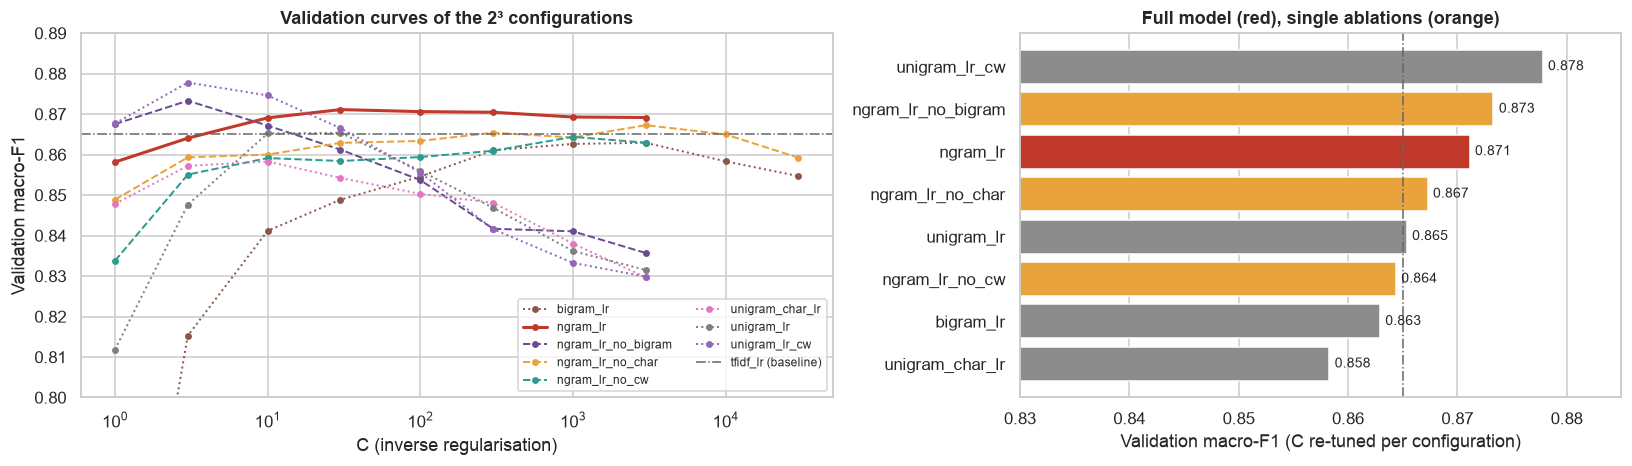

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.25, 1]})

# Left: validation curves of the eight configurations.
palette = dict(zip(CONFIG_IDS.values(), sns.color_palette("tab10", 8)))
palette.update({"ngram_lr": "#C0392B", "ngram_lr_no_bigram": "#6A4C93", "ngram_lr_no_char": "#E8A33D",
                "ngram_lr_no_cw": "#2A9D8F"})  # full model red, as in the right panel
for config, group in stage_b_log.groupby("config"):
    group = group.sort_values("C")
    style = "-" if config == "ngram_lr" else ("--" if config in ABLATIONS else ":")
    axes[0].plot(group["C"], group["val_macro_f1"], style, marker="o", ms=3.5, lw=2 if config == "ngram_lr" else 1.3,
                 color=palette[config], label=config)
axes[0].axhline(load_record("tfidf_lr", "validation")["macro_f1"], color="0.4", lw=1, ls="-.", label="tfidf_lr (baseline)")
axes[0].set_xscale("log")
axes[0].set_xlabel("C (inverse regularisation)")
axes[0].set_ylabel("Validation macro-F1")
axes[0].set_ylim(0.80, 0.89)
axes[0].set_title("Validation curves of the 2³ configurations")
axes[0].legend(fontsize=8, ncol=2, loc="lower right")

# Right: best validation score of each configuration.
order = factorial.index[::-1]
colors = ["#C0392B" if c == "ngram_lr" else ("#E8A33D" if c in ABLATIONS else "#8C8C8C") for c in order]
axes[1].barh(order, factorial.loc[order, "val macro-F1"], color=colors)
for k, c in enumerate(order):
    axes[1].text(factorial.loc[c, "val macro-F1"] + 0.0005, k, f"{factorial.loc[c, 'val macro-F1']:.3f}", va="center", fontsize=9)
axes[1].axvline(load_record("tfidf_lr", "validation")["macro_f1"], color="0.4", lw=1, ls="-.")
axes[1].set_xlim(0.83, 0.885)
axes[1].set_xlabel("Validation macro-F1 (C re-tuned per configuration)")
axes[1].set_title("Full model (red), single ablations (orange)")
axes[1].grid(axis="y", visible=False)
fig.tight_layout()
savefig(fig, "improved_ablation_validation.png")
plt.show()

### 4.2 Selecting the Improvement 1 model

The protocol selects the configuration with the highest validation macro-F1 among all eight cells. Validation differences of a few thousandths are within the noise of a 2,000-text split (the 95% bootstrap interval of a single model's macro-F1 is roughly ±0.02), so the selection is reported together with the ranking above, and the test-set significance tests in §6.2 decide which differences are real.

In [16]:
SELECTED_CONFIG = factorial.index[0]
selected_params = factorial.loc[SELECTED_CONFIG, "params"]
print(f"Selected Improvement 1 configuration: {SELECTED_CONFIG}")
print(f"  validation macro-F1 = {factorial.loc[SELECTED_CONFIG, 'val macro-F1']:.4f}, "
      f"C = {factorial.loc[SELECTED_CONFIG, 'selected C']:g}, sublinear_tf = {SUBLINEAR}")
print(f"Full model rank among the 8 configurations: {list(factorial.index).index('ngram_lr') + 1}")

Selected Improvement 1 configuration: unigram_lr_cw
  validation macro-F1 = 0.8778, C = 3, sublinear_tf = True
Full model rank among the 8 configurations: 3


## 5. Final training, test evaluation and saved models

Every configuration that takes part in a reported comparison is refitted on the training split with its selected hyper-parameters and scored on validation and test through `src/evaluate.py` (metrics in `results/metrics/`, per-example predictions with class probabilities in `results/predictions/`):

* the full model and its three ablations;
* `improved_lr`, the selected configuration, saved under a fixed role name so that later notebooks and the web service can load "the Improvement 1 model" without knowing which configuration won.

Two pipelines are saved to `models/classical/`: `improved_lr.joblib` (selected model) and `ngram_lr.joblib` (full model, which contains the character n-grams and is used for the misspelling demonstration in the web app).

In [17]:
def describe(config, params):
    bigram, char, cw = [k for k, v in CONFIG_IDS.items() if v == config][0]
    return (f"TF-IDF word {'(1,2)' if bigram else '(1,1)'}-grams"
            f"{' + char_wb (2,5)-grams (FeatureUnion)' if char else ''}, sublinear_tf={SUBLINEAR} + "
            f"LogisticRegression(C={params['clf__C']:g}, class_weight={'balanced' if cw else None}, tol=1e-6); "
            f"selected by validation macro-F1 (PredefinedSplit)")


final_models, val_preds, test_preds, test_probas, val_probas = {}, {}, {}, {}, {}
for config in ["ngram_lr", *ABLATIONS, SELECTED_CONFIG]:
    if config in final_models:
        continue
    params = factorial.loc[config, "params"]
    start = time.perf_counter()
    model = clone(make_pipeline(sublinear_tf=SUBLINEAR)).set_params(**params).fit(X_train, y_train)
    final_models[config] = model
    print(f"{config:<20} fitted in {time.perf_counter() - start:.0f} s")

# The selected configuration is evaluated and saved under the role name "improved_lr" only.
final_models["improved_lr"] = final_models.pop(SELECTED_CONFIG) if SELECTED_CONFIG not in ["ngram_lr", *ABLATIONS] \
    else final_models[SELECTED_CONFIG]

for name, model in final_models.items():
    config = SELECTED_CONFIG if name == "improved_lr" else name
    notes = describe(config, factorial.loc[config, "params"])
    if name == "improved_lr":
        notes = f"Selected Improvement 1 model (= {SELECTED_CONFIG}): " + notes
    for split, X, y, preds, probas in [("validation", X_val, y_val, val_preds, val_probas),
                                       ("test", X_test, y_test, test_preds, test_probas)]:
        proba = model.predict_proba(X)
        pred = proba.argmax(axis=1)
        evaluate(name, y, pred, split=split, y_proba=proba, texts=X, notes=notes, verbose=(split == "test"))
        preds[name], probas[name] = pred, proba

for name in ["improved_lr", "ngram_lr"]:
    joblib.dump(final_models[name], CLASSICAL_DIR / f"{name}.joblib")
    print(f"saved models/classical/{name}.joblib ({(CLASSICAL_DIR / f'{name}.joblib').stat().st_size / 1e6:.1f} MB)")

ngram_lr             fitted in 19 s
ngram_lr_no_char     fitted in 16 s
ngram_lr_no_cw       fitted in 21 s
ngram_lr_no_bigram   fitted in 9 s
unigram_lr_cw        fitted in 1 s
ngram_lr [test]  accuracy=0.8795  macro-F1=0.8281  weighted-F1=0.8804
ngram_lr_no_char [test]  accuracy=0.8780  macro-F1=0.8181  weighted-F1=0.8773
ngram_lr_no_cw [test]  accuracy=0.8790  macro-F1=0.8190  weighted-F1=0.8777
ngram_lr_no_bigram [test]  accuracy=0.8810  macro-F1=0.8326  weighted-F1=0.8836
improved_lr [test]  accuracy=0.8850  macro-F1=0.8429  weighted-F1=0.8880
saved models/classical/improved_lr.joblib (1.1 MB)
saved models/classical/ngram_lr.joblib (13.2 MB)


### 5.1 Extra row: Complement Naive Bayes

Complement Naive Bayes (Rennie et al., 2003) estimates, for each class $c$, the word distribution of all **other** classes, $\hat\theta_{\tilde c, t}$, and scores a document by how poorly it fits the complement: $\hat c = \arg\min_c \sum_t f_t \log \hat\theta_{\tilde c, t}$. Every complement contains many texts, even for *surprise*, so the estimates are less affected by the class imbalance that hurt Multinomial NB in `02_baselines`. Rennie et al. also recommend TF-IDF features with length normalisation, which is exactly the representation of the full model; the smoothing `alpha` is tuned with the same `PredefinedSplit`.

In [18]:
cnb_pipe = Pipeline([("features", clone(final_models["ngram_lr"].named_steps["features"])), ("clf", ComplementNB())])
cnb_search = grid_search(cnb_pipe, {"clf__alpha": [0.01, 0.03, 0.1, 0.3, 1.0, 3.0], "clf__norm": [False, True]})
cnb_log = pd.DataFrame(cnb_search.cv_results_["params"]).assign(val_macro_f1=cnb_search.cv_results_["mean_test_score"])
display(cnb_log.pivot(index="clf__norm", columns="clf__alpha", values="val_macro_f1").round(4))

best_cnb = cnb_log.sort_values("clf__alpha", ascending=False).loc[lambda d: d["val_macro_f1"].idxmax()]
cnb_params = {"clf__alpha": best_cnb["clf__alpha"], "clf__norm": bool(best_cnb["clf__norm"])}
cnb = clone(cnb_pipe).set_params(**cnb_params).fit(X_train, y_train)
final_models["ngram_cnb"] = cnb
cnb_notes = (f"TF-IDF word (1,2) + char_wb (2,5) (FeatureUnion, sublinear_tf={SUBLINEAR}) + "
             f"ComplementNB(alpha={cnb_params['clf__alpha']:g}, norm={cnb_params['clf__norm']}); selected by validation macro-F1")
for split, X, y, preds, probas in [("validation", X_val, y_val, val_preds, val_probas),
                                   ("test", X_test, y_test, test_preds, test_probas)]:
    proba = cnb.predict_proba(X)
    pred = cnb.predict(X)
    evaluate("ngram_cnb", y, pred, split=split, y_proba=proba, texts=X, notes=cnb_notes, verbose=(split == "test"))
    preds["ngram_cnb"], probas["ngram_cnb"] = pred, proba

12 candidates in 7 s


clf__alpha,0.01,0.03,0.10,0.30,1.00,3.00
clf__norm,,,,,,
False,0.8055,0.8382,0.8529,0.8412,0.7156,0.4618
True,0.6196,0.7231,0.8496,0.7492,0.5452,0.4041


ngram_cnb [test]  accuracy=0.8725  macro-F1=0.8242  weighted-F1=0.8713


In [19]:
# Sanity check: the saved pipelines accept raw strings and reproduce the saved predictions.
for name in ["improved_lr", "ngram_lr"]:
    reloaded = joblib.load(CLASSICAL_DIR / f"{name}.joblib")
    assert np.array_equal(reloaded.predict(X_test), test_preds[name])

demo = ["i feel so lonely without you", "i am thrilled about the trip", "i was shocked by the news",
        "i feel so lonley without you"]
reloaded = joblib.load(CLASSICAL_DIR / "ngram_lr.joblib")
demo_proba = pd.DataFrame(reloaded.predict_proba(demo), columns=LABELS, index=demo).round(3)
demo_proba["prediction"] = [LABELS[i] for i in reloaded.predict(demo)]
demo_proba

,sadness,joy,love,anger,fear,surprise,prediction
i feel so lonely without you,0.989,0.002,0.005,0.003,0.000,0.000,sadness
i am thrilled about the trip,0.006,0.985,0.001,0.001,0.007,0.000,joy
i was shocked by the news,0.000,0.000,0.000,0.000,0.000,1.000,surprise
i feel so lonley without you,0.783,0.111,0.077,0.022,0.004,0.003,sadness


## 6. Results

### 6.1 Summary tables

Both tables include the three baselines from `02_baselines`. The test table adds the 95% bootstrap confidence interval of macro-F1 (1,000 resamples of the 2,000 test texts).

In [20]:
BASELINE_IDS = ["bow_nb", "bow_lr", "tfidf_lr"]
NEW_IDS = ["ngram_cnb", "ngram_lr_no_char", "ngram_lr_no_cw", "ngram_lr_no_bigram", "ngram_lr", "improved_lr"]
DISPLAY_NAMES = {
    "bow_nb": "BoW + NB", "bow_lr": "BoW + LR", "tfidf_lr": "TF-IDF + LR",
    "ngram_cnb": "n-gram TF-IDF + CNB", "ngram_lr": "Full model", "ngram_lr_no_char": "Full − char",
    "ngram_lr_no_cw": "Full − class weights", "ngram_lr_no_bigram": "Full − bigrams",
    "improved_lr": f"Selected ({SELECTED_CONFIG})",
}

# Predictions of the baselines are read from the files written by 02_baselines.
for name in BASELINE_IDS:
    for split, store, pstore in [("validation", val_preds, val_probas), ("test", test_preds, test_probas)]:
        saved = pd.read_csv(ROOT / "results" / "predictions" / f"{name}__{split}.csv")
        store[name] = saved["pred"].to_numpy()
        pstore[name] = saved[[f"p_{c}" for c in LABELS]].to_numpy()
assert np.array_equal(pd.read_csv(ROOT / "results/predictions/tfidf_lr__test.csv")["true"], y_test)

print("Validation split (used for model selection)")
display(summary_table(["dummy_most_frequent", "dummy_stratified"] + BASELINE_IDS + NEW_IDS, split="validation").round(3))


def bootstrap_ci(y_true, y_pred, n_boot=1000, seed=SEED):
    # Percentile 95% confidence interval of macro-F1 over resampled test sets.
    rng = np.random.default_rng(seed)
    n = len(y_true)
    scores = [macro_f1(y_true[idx], y_pred[idx]) for idx in (rng.integers(0, n, n) for _ in range(n_boot))]
    return np.percentile(scores, [2.5, 97.5])


ALL_IDS = BASELINE_IDS + NEW_IDS
test_table = summary_table(ALL_IDS, split="test")
ci = {name: bootstrap_ci(y_test, test_preds[name]) for name in ALL_IDS}
test_table.insert(2, "macro_f1_ci95", [f"[{ci[n][0]:.3f}, {ci[n][1]:.3f}]" for n in ALL_IDS])
print("Test split (final evaluation)")
display(test_table.round(3))

Validation split (used for model selection)


,accuracy,macro_f1,weighted_f1,f1_sadness,f1_joy,f1_love,f1_anger,f1_fear,f1_surprise
model,,,,,,,,,
dummy_most_frequent,0.352,0.087,0.183,0.000,0.521,0.000,0.000,0.000,0.000
dummy_stratified,0.244,0.171,0.244,0.297,0.349,0.092,0.144,0.094,0.052
bow_nb,0.808,0.719,0.799,0.841,0.860,0.689,0.789,0.751,0.382
bow_lr,0.889,0.856,0.889,0.909,0.923,0.816,0.893,0.819,0.778
tfidf_lr,0.894,0.865,0.894,0.912,0.924,0.826,0.897,0.834,0.797
ngram_cnb,0.882,0.853,0.881,0.911,0.903,0.811,0.888,0.816,0.789
ngram_lr_no_char,0.899,0.867,0.899,0.921,0.925,0.829,0.911,0.839,0.778
ngram_lr_no_cw,0.894,0.864,0.894,0.919,0.918,0.812,0.902,0.843,0.792
ngram_lr_no_bigram,0.894,0.873,0.895,0.916,0.910,0.843,0.907,0.845,0.818


Test split (final evaluation)


,accuracy,macro_f1,macro_f1_ci95,weighted_f1,f1_sadness,f1_joy,f1_love,f1_anger,f1_fear,f1_surprise
model,,,,,,,,,,
bow_nb,0.802,0.695,"[0.667, 0.722]",0.792,0.843,0.858,0.595,0.781,0.733,0.360
bow_lr,0.883,0.831,"[0.808, 0.854]",0.882,0.927,0.911,0.741,0.880,0.842,0.688
tfidf_lr,0.882,0.832,"[0.808, 0.853]",0.880,0.919,0.910,0.761,0.876,0.833,0.694
ngram_cnb,0.872,0.824,"[0.798, 0.847]",0.871,0.915,0.902,0.708,0.859,0.837,0.724
ngram_lr_no_char,0.878,0.818,"[0.793, 0.841]",0.877,0.921,0.907,0.747,0.878,0.841,0.614
ngram_lr_no_cw,0.879,0.819,"[0.794, 0.841]",0.878,0.919,0.915,0.756,0.865,0.831,0.629
ngram_lr_no_bigram,0.881,0.833,"[0.809, 0.853]",0.884,0.920,0.918,0.782,0.875,0.825,0.675
ngram_lr,0.880,0.828,"[0.805, 0.850]",0.880,0.919,0.914,0.772,0.865,0.837,0.662
improved_lr,0.885,0.843,"[0.820, 0.862]",0.888,0.925,0.910,0.774,0.886,0.860,0.701


### 6.2 Significance tests

All comparisons are paired, on the same 2,000 test texts (A → B; $b$ = texts only A classifies correctly, $c$ = texts only B classifies correctly; $\Delta = \text{macro-F1}_B - \text{macro-F1}_A$ with its 95% paired-bootstrap interval, 2,000 resamples).

* **Ablations:** ablated model → full model, so $\Delta$ is the contribution of the component.
* **Improvement over the reference baseline:** `tfidf_lr` → full model, and `tfidf_lr` → selected model.
* **Naive Bayes family:** `bow_nb` → `ngram_cnb`.

Six McNemar tests are run on the same test set, so the p-values are also adjusted with the **Holm–Bonferroni** procedure, which controls the probability of at least one false positive across the family.

In [21]:
def holm(p_values):
    # Holm-Bonferroni adjusted p-values (step-down, monotone).
    p = np.asarray(p_values, dtype=float)
    order = np.argsort(p)
    adjusted = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adjusted[i] = min(1.0, running)
    return adjusted


COMPARISONS = [
    ("ngram_lr_no_char", "ngram_lr", "ablation: + character n-grams"),
    ("ngram_lr_no_cw", "ngram_lr", "ablation: + class weights"),
    ("ngram_lr_no_bigram", "ngram_lr", "ablation: + word bigrams"),
    ("tfidf_lr", "ngram_lr", "baseline → full model"),
    ("tfidf_lr", "improved_lr", "baseline → selected model"),
    ("bow_nb", "ngram_cnb", "Multinomial NB → Complement NB (n-gram TF-IDF)"),
]

rows = []
for a, b, question in COMPARISONS:
    mc = mcnemar_test(y_test, test_preds[a], test_preds[b])
    bs = paired_bootstrap(y_test, test_preds[a], test_preds[b], n_boot=2000, seed=SEED)
    rows.append({
        "comparison (A → B)": f"{a} → {b}",
        "question": question,
        "b (only A correct)": mc["b"],
        "c (only B correct)": mc["c"],
        "McNemar p": mc["p_value"],
        "Δ macro-F1": bs["delta"],
        "95% CI of Δ": f"[{bs['ci_low']:+.3f}, {bs['ci_high']:+.3f}]",
        "CI excludes 0": (bs["ci_low"] > 0) or (bs["ci_high"] < 0),
    })
significance = pd.DataFrame(rows).set_index("comparison (A → B)")
significance.insert(5, "Holm-adjusted p", holm(significance["McNemar p"]))
significance.to_csv(METRICS_DIR / "significance_improved_classical_test.csv")
display(significance.style.format({"McNemar p": "{:.2g}", "Holm-adjusted p": "{:.2g}", "Δ macro-F1": "{:+.3f}"}))

,question,b (only A correct),c (only B correct),McNemar p,Δ macro-F1,Holm-adjusted p,95% CI of Δ,CI excludes 0
comparison (A → B),,,,,,,,
ngram_lr_no_char → ngram_lr,ablation: + character n-grams,55,58,0.85,+0.010,1,"[-0.006, +0.027]",False
ngram_lr_no_cw → ngram_lr,ablation: + class weights,30,31,1,+0.009,1,"[-0.005, +0.023]",False
ngram_lr_no_bigram → ngram_lr,ablation: + word bigrams,43,40,0.83,-0.005,1,"[-0.018, +0.009]",False
tfidf_lr → ngram_lr,baseline → full model,71,67,0.8,-0.004,1,"[-0.022, +0.015]",False
tfidf_lr → improved_lr,baseline → selected model,71,78,0.62,+0.011,1,"[-0.010, +0.031]",False
bow_nb → ngram_cnb,Multinomial NB → Complement NB (n-gram TF-IDF),69,211,3.6e-17,+0.129,2.1e-16,"[+0.097, +0.161]",True


McNemar's test only counts *which* texts are right or wrong, so it responds to changes in accuracy. A component that moves errors from small classes to large classes can leave accuracy unchanged while changing macro-F1; this is why the bootstrap interval of $\Delta$ macro-F1 is read alongside it, and why the two tests can disagree for the class-weight ablation.

### 6.3 Per-class effects

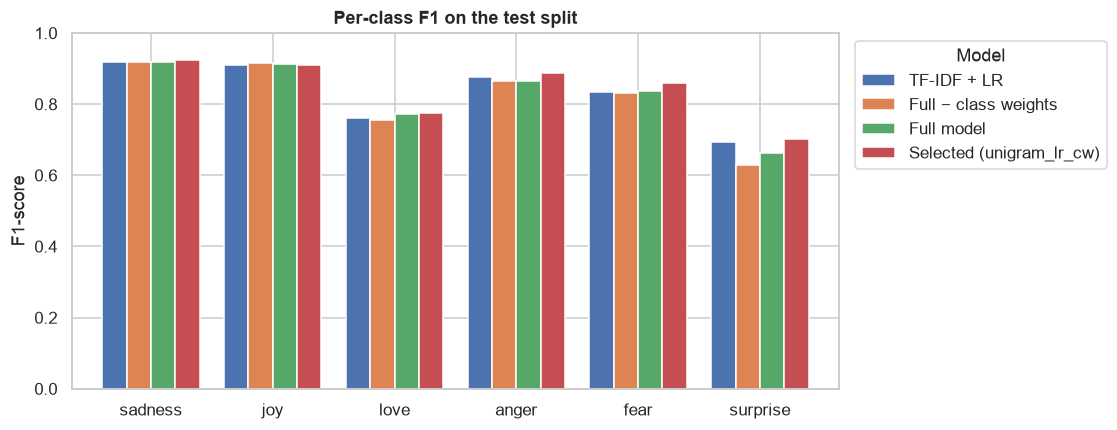

,love precision,love recall,surprise precision,surprise recall,accuracy
model,,,,,
TF-IDF + LR,0.795,0.730,0.764,0.636,0.882
Full − class weights,0.784,0.730,0.672,0.591,0.879
Full model,0.747,0.799,0.618,0.712,0.880
Selected (unigram_lr_cw),0.683,0.893,0.614,0.818,0.885


Number of test texts predicted as each class:


,sadness,joy,love,anger,fear,surprise
gold (test),581,695,159,275,224,66
TF-IDF + LR,586,734,146,266,213,55
Full − class weights,579,728,148,280,207,58
Full model,561,695,170,287,211,76
Selected (unigram_lr_cw),543,654,208,287,220,88


In [22]:
focus = ["tfidf_lr", "ngram_lr_no_cw", "ngram_lr", "improved_lr"]
ax = plot_per_class_f1(test_table.loc[focus].rename(index=DISPLAY_NAMES),
                       title="Per-class F1 on the test split", save_as="improved_per_class_f1.png")
plt.show()

# Recall and precision of the two minority classes, with and without class weights.
rows = []
for name in focus:
    rec = load_record(name, "test")["per_class"]
    rows.append({"model": DISPLAY_NAMES[name],
                 **{f"{c} {m}": rec[c][m] for c in ["love", "surprise"] for m in ["precision", "recall"]},
                 "accuracy": load_record(name, "test")["accuracy"]})
display(pd.DataFrame(rows).set_index("model").round(3))

# How often each class is predicted, compared with its true frequency.
pred_share = pd.DataFrame({DISPLAY_NAMES[n]: np.bincount(test_preds[n], minlength=6) for n in focus}, index=LABELS)
pred_share.insert(0, "gold (test)", np.bincount(y_test, minlength=6))
print("Number of test texts predicted as each class:")
display(pred_share.T)

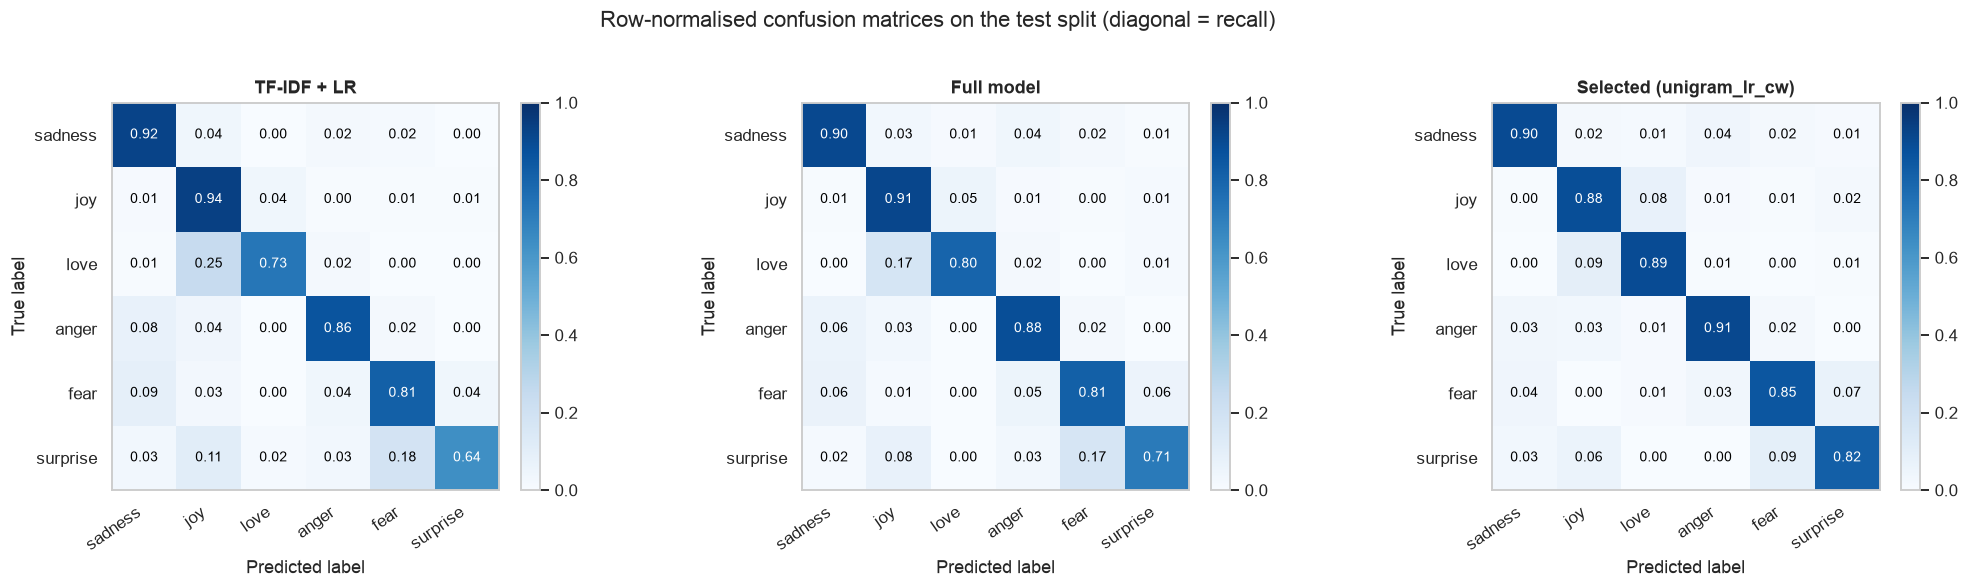

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
for ax, name in zip(axes, ["tfidf_lr", "ngram_lr", "improved_lr"]):
    plot_confusion_matrix(y_test, test_preds[name], title=DISPLAY_NAMES[name], ax=ax)
fig.suptitle("Row-normalised confusion matrices on the test split (diagonal = recall)", y=1.02)
fig.tight_layout()
savefig(fig, "improved_confusion_matrices.png")
plt.show()

### 6.4 Probability quality

Class weights optimise a re-weighted loss, so the model estimates the class posteriors of a *balanced* training set: the minority classes receive systematically inflated probabilities. If the original class priors $\pi_c$ are needed (for example to display honest confidences in the web app), the outputs can be corrected by Bayes' rule,

$$
\tilde P(c \mid \mathbf{x}) = \frac{P_{\text{bal}}(c \mid \mathbf{x})\, \pi_c}{\sum_k P_{\text{bal}}(k \mid \mathbf{x})\, \pi_k},
$$

which undoes the uniform prior implied by the balanced weights. The correction changes the arg-max as well, so the displayed probabilities would no longer agree with the predicted label.

**Temperature scaling** (Guo et al., 2017) is the alternative that keeps the labels unchanged: the log-probabilities are divided by a single scalar $T$ before the softmax, $\tilde P(c \mid \mathbf{x}) \propto P(c \mid \mathbf{x})^{1/T}$. $T > 1$ softens over-confident outputs, $T < 1$ sharpens under-confident ones, and the arg-max is unchanged. $T$ is fitted by minimising the log-loss on the **validation** split and then applied to the test split. The fitted values are saved to `results/metrics/temperature_improved_classical.json` for the web service.

In [24]:
from scipy.optimize import minimize_scalar

prior = counts / counts.sum()


def prior_correct(proba):
    adjusted = proba * prior
    return adjusted / adjusted.sum(axis=1, keepdims=True)


def apply_temperature(proba, T):
    logits = np.log(np.clip(proba, 1e-12, 1.0)) / T
    logits -= logits.max(axis=1, keepdims=True)
    scaled = np.exp(logits)
    return scaled / scaled.sum(axis=1, keepdims=True)


def fit_temperature(proba, y):
    # Single temperature that minimises the log-loss on the given (validation) predictions.
    result = minimize_scalar(lambda T: log_loss(y, apply_temperature(proba, T), labels=LABEL_IDS),
                             bounds=(0.05, 10.0), method="bounded")
    return float(result.x)


temperatures = {}


rows = []
for name in ["tfidf_lr", "ngram_lr_no_cw", "ngram_lr", "improved_lr", "ngram_cnb"]:
    proba = test_probas[name]
    confidence = proba.max(axis=1)
    correct = test_preds[name] == y_test
    row = {
        "model": DISPLAY_NAMES[name],
        "test log-loss": log_loss(y_test, proba, labels=LABEL_IDS),
        "mean confidence": confidence.mean(),
        "accuracy": correct.mean(),
        "wrong with confidence > 0.9": int(np.sum(~correct & (confidence > 0.9))),
    }
    uses_weights = name in final_models and getattr(final_models[name].named_steps["clf"], "class_weight", None) == "balanced"
    row["log-loss after prior correction"] = log_loss(y_test, prior_correct(proba), labels=LABEL_IDS) if uses_weights else np.nan
    T = fit_temperature(val_probas[name], y_val)
    temperatures[name] = T
    scaled = apply_temperature(proba, T)
    row["T (fitted on validation)"] = T
    row["log-loss after temperature scaling"] = log_loss(y_test, scaled, labels=LABEL_IDS)
    row["mean confidence after scaling"] = scaled.max(axis=1).mean()
    rows.append(row)
display(pd.DataFrame(rows).set_index("model").round(3))
with open(METRICS_DIR / "temperature_improved_classical.json", "w", encoding="utf-8") as fh:
    json.dump({k: round(v, 4) for k, v in temperatures.items()}, fh, indent=2)

,test log-loss,mean confidence,accuracy,wrong with confidence > 0.9,log-loss after prior correction,T (fitted on validation),log-loss after temperature scaling,mean confidence after scaling
model,,,,,,,,
TF-IDF + LR,0.329,0.869,0.882,33,NaN,0.899,0.325,0.886
Full − class weights,0.361,0.931,0.879,81,NaN,1.434,0.328,0.892
Full model,0.333,0.867,0.880,38,0.354,0.854,0.328,0.893
Selected (unigram_lr_cw),0.474,0.722,0.885,12,0.448,0.511,0.349,0.889
n-gram TF-IDF + CNB,0.489,0.741,0.872,11,NaN,0.539,0.399,0.879


## 7. Where does each component matter?

Average scores can hide effects that are concentrated in a subset of texts. Each component has a specific target, so it is evaluated on that target.

### 7.1 Character n-grams and unseen words

If the subword argument holds, adding character n-grams should help most on texts that contain a word never seen in training (31.5% of test texts).

In [25]:
def slice_comparison(mask, a, b, slice_names):
    # Macro-F1 of models a and b inside and outside a slice, with bootstrap CI of the difference.
    rows = []
    for inside, label in [(False, slice_names[0]), (True, slice_names[1])]:
        sel = mask == inside
        y, pa, pb = y_test[sel], test_preds[a][sel], test_preds[b][sel]
        bs = paired_bootstrap(y, pa, pb, n_boot=2000, seed=SEED)
        mc = mcnemar_test(y, pa, pb)
        rows.append({"slice": label, "n": int(sel.sum()), f"{a}": macro_f1(y, pa), f"{b}": macro_f1(y, pb),
                     "Δ macro-F1": bs["delta"], "95% CI of Δ": f"[{bs['ci_low']:+.3f}, {bs['ci_high']:+.3f}]",
                     "b / c": f"{mc['b']} / {mc['c']}", "McNemar p": mc["p_value"]})
    return pd.DataFrame(rows).set_index("slice")


fmt = {"Δ macro-F1": "{:+.3f}", "McNemar p": "{:.2g}"}
print("Character n-grams (full − char → full):")
display(slice_comparison(oov_mask["test"], "ngram_lr_no_char", "ngram_lr", OOV_LEVELS).style.format(fmt, precision=3))
print("Reference baseline → selected model:")
display(slice_comparison(oov_mask["test"], "tfidf_lr", "improved_lr", OOV_LEVELS).style.format(fmt, precision=3))

# Which words are unseen in the clean test texts?
from collections import Counter
unseen_counts = Counter(w for t in X_test for w in unseen_words(t, train_vocab))
print(f"Most frequent unseen words in the test split ({len(unseen_counts):,} types, "
      f"{sum(unseen_counts.values()):,} tokens):")
print(", ".join(f"{w} ({n})" for w, n in unseen_counts.most_common(30)))

Character n-grams (full − char → full):


,n,ngram_lr_no_char,ngram_lr,Δ macro-F1,95% CI of Δ,b / c,McNemar p
slice,,,,,,,
all words seen in training,1370,0.819,0.835,+0.017,"[-0.001, +0.036]",27 / 37,0.26
>= 1 unseen word,630,0.813,0.810,-0.003,"[-0.035, +0.026]",28 / 21,0.39


Reference baseline → selected model:


,n,tfidf_lr,improved_lr,Δ macro-F1,95% CI of Δ,b / c,McNemar p
slice,,,,,,,
all words seen in training,1370,0.847,0.845,-0.001,"[-0.025, +0.022]",44 / 44,0.92
>= 1 unseen word,630,0.798,0.835,+0.037,"[-0.000, +0.076]",27 / 34,0.44


Most frequent unseen words in the test split (972 types, 1,040 tokens):
elevator (5), momo (4), refuge (3), volunteering (3), treasures (3), bridesmaids (3), mashed (3), blogged (3), lifestyles (2), claudia (2), foresee (2), mabel (2), touring (2), sandpiper (2), client (2), ellie (2), storyline (2), supplies (2), prepares (2), asa (2), hs (2), productions (2), fondling (2), feng (2), tasted (2), standard (2), strides (2), charities (2), marius (2), schoolboy (2)


**What does the model infer from the spelling alone?** A text that consists of a single unseen word is an empty vector for a word-level model: the prediction then depends only on the intercepts, i.e. on the class priors. The full model still sees the word's character n-grams. The table uses deliberate misspellings of emotion words, none of which occurs in the training data.

In [26]:
probe_words = ["lonley", "miserible", "hapyness", "joyfull", "adorre", "romantik", "furiuos", "iritated",
               "terrifed", "anxiuos", "astonsihed", "shockd"]
assert not any(w in train_vocab for w in probe_words)

rows = []
for word in probe_words:
    full_p = final_models["ngram_lr"].predict_proba([word])[0]
    noc_p = final_models["ngram_lr_no_char"].predict_proba([word])[0]
    rows.append({"unseen word": word,
                 "full model": f"{LABELS[full_p.argmax()]} ({full_p.max():.2f})",
                 "full − char": f"{LABELS[noc_p.argmax()]} ({noc_p.max():.2f})",
                 "char n-grams seen in training": f"{np.mean([g in char_vocab for g in analyse(word)]):.0%}"})
display(pd.DataFrame(rows).set_index("unseen word"))

,full model,full − char,char n-grams seen in training
unseen word,,,
lonley,sadness (0.61),joy (0.61),73%
miserible,sadness (1.00),joy (0.61),88%
hapyness,joy (0.53),joy (0.61),73%
joyfull,joy (0.99),joy (0.61),100%
adorre,joy (0.30),joy (0.61),82%
romantik,love (0.99),joy (0.61),87%
furiuos,anger (0.76),joy (0.61),62%
iritated,anger (0.99),joy (0.61),93%
terrifed,fear (0.86),joy (0.61),83%


### 7.2 Word bigrams and negation

Bigrams are meant to capture short-range negation. The comparison below splits the test set by the negation-cue slice of `01_eda`, and the following cell lists the bigrams containing a negation word with the largest weights in the full model.

In [27]:
print("Word bigrams (full − bigrams → full):")
display(slice_comparison(neg_mask["test"], "ngram_lr_no_bigram", "ngram_lr",
                         ["without negation cue", "with negation cue"]).style.format(fmt, precision=3))

feature_names = final_models["ngram_lr"].named_steps["features"].get_feature_names_out()
W = final_models["ngram_lr"].named_steps["clf"].coef_
NEG_WORDS = {"not", "no", "never", "dont", "didnt", "cant", "nothing", "without", "isnt", "wasnt"}
is_neg_bigram = np.array([n.startswith("word__") and " " in n and n[6:].split()[0] in NEG_WORDS for n in feature_names])
neg_idx = np.where(is_neg_bigram)[0]
rows = []
for c, label in enumerate(LABELS):
    top = neg_idx[np.argsort(W[c, neg_idx])[::-1][:5]]
    rows.append({"emotion": label, "top negation bigrams (weight)": ", ".join(f"{feature_names[j][6:]} ({W[c, j]:.2f})" for j in top)})
display(pd.DataFrame(rows).set_index("emotion"))

idx = {n: j for j, n in enumerate(feature_names)}
pairs = [("happy", "not happy"), ("sure", "not sure"), ("good", "not good"), ("care", "dont care")]
weight_rows = {f"word__{t}": W[:, idx[f"word__{t}"]] for pair in pairs for t in pair if f"word__{t}" in idx}
weights_table = pd.DataFrame(weight_rows, index=LABELS).T.rename(index=lambda s: s[6:]).round(2)
bi_index = bi_vec.vocabulary_
weights_table.insert(0, "training texts", [int(bigram_df[bi_index[t]]) for t in weights_table.index])
display(weights_table)

Word bigrams (full − bigrams → full):


,n,ngram_lr_no_bigram,ngram_lr,Δ macro-F1,95% CI of Δ,b / c,McNemar p
slice,,,,,,,
without negation cue,1430,0.846,0.832,-0.014,"[-0.031, +0.003]",34 / 25,0.3
with negation cue,570,0.798,0.818,+0.020,"[-0.001, +0.043]",9 / 15,0.31


,top negation bigrams (weight)
emotion,
sadness,"cant help (0.93), no ones (0.88), didnt know (0.86), without feeling (0.77), not going (0.72)"
joy,"not feeling (2.20), not anxious (1.56), never feel (1.53), didnt feel (1.33), not just (1.17)"
love,"not caring (1.32), not accepted (1.05), didnt do (0.87), not really (0.83), not feeling (0.81)"
anger,"no response (2.09), no description (2.03), without any (1.07), not heartless (0.99), not to (0.86)"
fear,"without feeling (2.37), not feel (2.06), not having (1.21), never want (1.03), not an (0.98)"
surprise,"not impressed (0.84), without him (0.80), not sure (0.75), without moment (0.74), isnt real (0.70)"


,training texts,sadness,joy,love,anger,fear,surprise
happy,234,-2.02,3.05,-0.34,-0.06,-0.66,0.03
not happy,2,0.05,-0.03,-0.00,-0.00,-0.00,-0.02
sure,231,-0.67,2.36,-0.72,0.87,-1.08,-0.75
not sure,50,0.45,-0.40,-0.42,-0.29,-0.09,0.75
good,376,0.00,1.61,-0.21,-0.18,-0.50,-0.73
not good,14,0.53,-0.12,0.05,-0.09,-0.31,-0.06
care,100,0.25,-0.04,-0.07,0.63,-0.63,-0.15
dont care,2,-0.06,0.09,0.08,-0.04,-0.06,-0.01


### 7.3 Stress test: misspellings

The test texts are clean, but the web application will receive typed input with spelling mistakes (and, through speech recognition, occasional wrong words). The stress test perturbs the test texts with random edits — deleting, swapping, duplicating or replacing one interior character — applied to each word of four or more letters with probability $p$. Gold labels are unchanged, and the same perturbed texts are given to every model (seed 42).

In [28]:
def misspell(text, p, rng):
    # Apply one random character edit to each word of >= 4 letters with probability p.
    out = []
    for word in text.split():
        if len(word) >= 4 and rng.random() < p:
            i = int(rng.integers(1, len(word) - 1))  # interior position; the first letter is kept
            edit = rng.integers(4)
            if edit == 0:
                word = word[:i] + word[i + 1:]                             # deletion
            elif edit == 1:
                word = word[:i] + word[i + 1] + word[i] + word[i + 2:]     # swap with next character
            elif edit == 2:
                word = word[:i] + word[i] + word[i:]                       # duplication
            else:
                word = word[:i] + chr(int(rng.integers(97, 123))) + word[i + 1:]  # replacement
        out.append(word)
    return " ".join(out)


rng = np.random.default_rng(SEED)
print("Examples (p = 0.3):")
for text in X_test[:4]:
    print(f"  original:  {text}\n  perturbed: {misspell(text, 0.3, rng)}")

NOISE_LEVELS = [0.0, 0.1, 0.2, 0.3, 0.5]
STRESS_IDS = ["tfidf_lr", "ngram_lr_no_char", "ngram_lr_no_bigram", "ngram_lr", "improved_lr"]
stress_rows = []
for p in NOISE_LEVELS:
    rng = np.random.default_rng(SEED)
    noisy = [misspell(t, p, rng) for t in X_test]
    noisy_oov = unseen_word_mask(noisy, train_vocab).mean()
    for name in STRESS_IDS:
        model = final_models[name] if name in final_models else joblib.load(CLASSICAL_DIR / f"{name}.joblib")
        stress_rows.append({"p": p, "model": name, "macro_f1": macro_f1(y_test, model.predict(noisy)),
                            "texts with unseen word": noisy_oov})
stress = pd.DataFrame(stress_rows)
stress.to_csv(METRICS_DIR / "stress_misspellings_test.csv", index=False)
display(stress.pivot(index="model", columns="p", values="macro_f1").loc[STRESS_IDS].round(3))

Examples (p = 0.3):
  original:  im feeling rather rotten so im not very ambitious right now
  perturbed: im feeling rather rotten so im not very ambitious right now
  original:  im updating my blog because i feel shitty
  perturbed: im updatlng my blog because i feel shitty
  original:  i never make her separate from me because i don t ever want her to feel like i m ashamed with her
  perturbed: i never maake her separahe from me because i don t ever want her to feel liek i m ashaamed with her
  original:  i left with my bouquet of red and yellow tulips under my arm feeling slightly more optimistic than when i arrived
  perturbed: i left with my bouquet of red and yellow tulips udner my arm feeling sllightly more optimistic than when i arrived


p,0.0,0.1,0.2,0.3,0.5
model,,,,,
tfidf_lr,0.832,0.787,0.747,0.702,0.596
ngram_lr_no_char,0.818,0.776,0.740,0.693,0.578
ngram_lr_no_bigram,0.833,0.808,0.789,0.771,0.692
ngram_lr,0.828,0.800,0.788,0.764,0.696
improved_lr,0.843,0.798,0.757,0.715,0.598


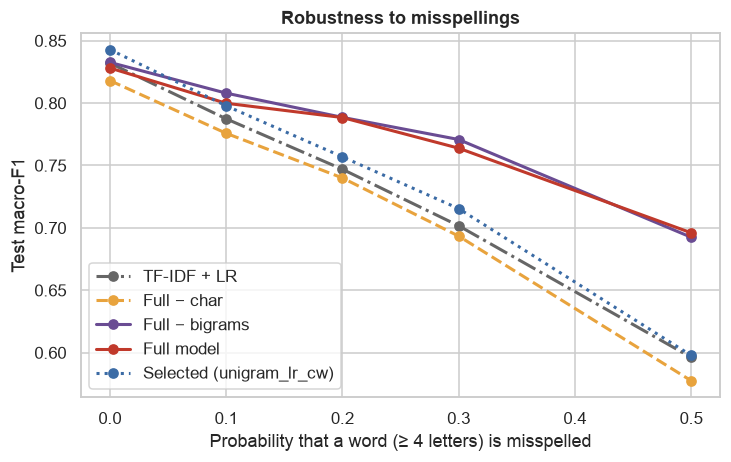

Relative loss of macro-F1 at p = 0.3:
model
tfidf_lr              15.7%
ngram_lr_no_char      15.2%
ngram_lr_no_bigram     7.4%
ngram_lr               7.8%
improved_lr           15.1%


In [29]:
fig, ax = plt.subplots(figsize=(7.5, 4.3))
style = {"tfidf_lr": ("0.4", "-."), "ngram_lr_no_char": ("#E8A33D", "--"), "ngram_lr": ("#C0392B", "-"),
         "ngram_lr_no_bigram": ("#6A4C93", "-"), "improved_lr": ("#3B6BA5", ":")}
for name in STRESS_IDS:
    part = stress[stress["model"] == name]
    color, ls = style[name]
    ax.plot(part["p"], part["macro_f1"], ls, marker="o", color=color, lw=2, label=DISPLAY_NAMES[name])
ax.set_xlabel("Probability that a word (≥ 4 letters) is misspelled")
ax.set_ylabel("Test macro-F1")
ax.set_title("Robustness to misspellings")
ax.legend()
savefig(fig, "improved_misspelling_stress.png")
plt.show()

drop = stress.pivot(index="model", columns="p", values="macro_f1")
print("Relative loss of macro-F1 at p = 0.3:")
print((1 - drop[0.3] / drop[0.0]).loc[STRESS_IDS].map("{:.1%}".format).to_string())

## 8. Discussion

### 8.1 Overall results

The full model (word 1–2-grams + character 2–5-grams + class weights) reaches a validation macro-F1 of 0.871 and a test macro-F1 of 0.828 (accuracy 0.880). This is practically the same as the reference baseline `tfidf_lr` (0.865 / 0.832; $\Delta$ on test −0.004, 95% CI [−0.022, +0.014]). The $2^3$ ablation shows why. **Class weights are the only component that helps consistently**, while character n-grams and word bigrams add roughly 170,000 features without improving the benchmark score.

Following the protocol, the configuration with the highest validation macro-F1 was selected as `improved_lr`: TF-IDF **unigrams** with sublinear tf, class weights and C = 3 (validation 0.878). It is also the best model on test (accuracy 0.885, macro-F1 0.843 [0.820, 0.862]). The gain over `tfidf_lr` is +0.011, but the interval [−0.010, +0.031] includes zero and McNemar's test finds no difference (71 vs. 78 texts, p = 0.62). Improvement 1 is therefore **not a significant improvement in macro-F1**. Its value lies in what the controlled comparisons reveal and in the robustness of the character n-grams under misspellings (§8.3).

None of the three single-variable ablations is significant on test. Character n-grams: +0.008 [−0.007, +0.024], McNemar p = 0.85. Class weights: +0.008 [−0.006, +0.021], p = 0.90. Word bigrams: −0.005 [−0.018, +0.009], p = 0.83. All Holm-adjusted p-values equal 1. The only significant comparison of the notebook is Complement vs. Multinomial Naive Bayes (§8.6).

### 8.2 Character n-grams: the FastText subword idea and the unseen-word rate

The mechanism works as intended. Every one of the 1,884 unseen word types in the validation and test texts shares at least one character n-gram with the training data, and on average 88.8% of their n-grams are known (§2.1). The probe in §7.1 makes this visible. For a single unseen word, the word-level model has an empty feature vector and falls back on its intercepts (always *joy*, p = 0.60). The full model recovers the intended emotion for 10 of 12 misspellings purely from the spelling (*lonley* → sadness, *romantik* → love, *iritated* → anger, *terrifed* → fear, *shockd* → surprise). This is the FastText argument from Lecture 6: words that share sub-strings share parameters, so an out-of-vocabulary word is no longer invisible.

On the clean benchmark, however, this hardly matters, and the EDA numbers explain why.

* **Unseen words are rare.** Only 2.7% of validation and test tokens are unseen (01_eda §4). Although 31.5% of test texts contain one, these 630 texts contain on average 1.7 unseen words (1,040 tokens), against a median text length of 17 words.
* **Unseen words are not the emotion words.** The most frequent unseen test words are names and content nouns (*elevator, momo, refuge, bridesmaids, claudia*). The word that carries the label, typically the adjective after *i feel*, is almost always in the training vocabulary. Accordingly, adding character n-grams does not help on the texts that contain an unseen word ($\Delta$ −0.009 [−0.037, +0.020], n = 630).
* **The extra features cost variance.** The character block adds 59,825 features. In the unigram models it lowers validation macro-F1 by 0.005–0.008 (§4).

FastText's subword vectors were shown to help most for morphologically rich languages and for rare words (Bojanowski et al., 2017). Short English texts with a small, frequent emotion vocabulary leave little room for that benefit. **Spelling errors** turn the emotion word itself into an unseen word, and there the benefit appears clearly (§7.3). With 30% of longer words misspelled, the word-only models lose 15–16% of their macro-F1, while the models with character n-grams lose 7.4–7.6% (0.771 and 0.765 vs. 0.715 for `improved_lr`). At 50% the gap is about 0.10. The models with character n-grams overtake `improved_lr` once about one word in ten is misspelled.

### 8.3 Word bigrams and negation

The bigram vocabulary is large and sparse: 109,796 bigrams, 76.6% of which occur in only one training text. The bigrams that matter most for negation are especially rare. *not happy* occurs in two training texts and receives weights of at most 0.05 in absolute value, against 3.05 for *happy* → joy, so the model still reads *not happy* as *happy*. Only more frequent phrases receive useful weights. For example, *not sure* (50 texts) pushes towards surprise (+0.75) and against joy (−0.40), partly offsetting *sure* → joy (+2.36).

The slice analysis shows the trade-off. On texts with a negation cue, bigrams improve macro-F1 by +0.020 [−0.002, +0.044]. On the other 72% of the test set they lower it by −0.014 [−0.031, +0.003], and the net effect is −0.005. Bigrams therefore help where they were meant to, but only slightly, and they pay for it with noise elsewhere.

Many of the largest negation-bigram weights do not reverse polarity at all. *not feeling* (132 texts) is the strongest negation bigram for joy (+2.20), and *without feeling* the strongest for fear (+2.37). As 01_eda showed, the labels of this corpus come from distant supervision, so a negated emotion word often keeps the label of the word itself. The bigram weights then describe frequent phrasings of the corpus rather than the meaning of negation. Modelling negation compositionally needs word order beyond adjacent pairs; this is the task of the BiLSTM (Improvement 2) and BERT (Improvement 3), and the negation behavioural tests in `08_error_analysis` will measure it directly.

### 8.4 Class weights

Class weights are the only component with a positive effect in all four pairs of the factorial design on validation (+0.003 to +0.015). On test, the full model with weights has exactly the same accuracy as without them (32 vs. 32 discordant texts, McNemar p = 0.90). The weights do not make the model more accurate; they **redistribute its errors**:

* *love* recall rises from 0.717 to 0.799 and *surprise* recall from 0.606 to 0.712. Precision falls from 0.781 to 0.747 and from 0.667 to 0.618 respectively.
* *surprise* is now predicted 76 times (gold: 66) instead of 60. With weaker regularisation (`improved_lr`, C = 3), *love* is predicted 208 times for 159 gold texts, so the minority classes are over-predicted and *joy* and *sadness* lose recall.

Macro-F1 gives the six classes equal weight, so this trade-off raises the score (+0.008, not significant on test). Accuracy and weighted-F1 do not reward it, which is why McNemar's test and the bootstrap interval of $\Delta$ macro-F1 must be read together.

The weights also change the **probabilities** (§6.4). `improved_lr` is under-confident: its mean confidence is 0.722 for an accuracy of 0.885, and its test log-loss is 0.474 against 0.329 for `tfidf_lr`. Two factors contribute: the balanced prior, which spreads probability mass towards the minority classes, and the strong regularisation (C = 3), which shrinks all scores. Correcting the prior with Bayes' rule only partly repairs this (log-loss 0.448) and changes the predicted labels. Temperature scaling with $T = 0.51$, fitted on validation, lowers the test log-loss to 0.349 and leaves every label unchanged. The web application should therefore display temperature-scaled probabilities; the fitted values are saved in `results/metrics/temperature_improved_classical.json`.

### 8.5 Why the simplest configuration wins

Two observations explain why adding features does not help a linear model on this dataset.

1. **Over-parameterisation.** As blocks are added, the selected `C` grows: 3–10 for the unigram models, 30 for the full model and 1,000–3,000 for the other bigram models. Rare n-gram features only receive useful weights when the penalty is weak, and a weak penalty lets the model fit the training set almost perfectly: training macro-F1 is 0.997 for every configuration with bigrams, against 0.959 for `improved_lr`. With 185,000 features for 16,000 texts, the extra capacity is spent on memorising rare phrases rather than on generalisable evidence.
2. **The dataset's shortcut.** 97.3% of texts contain a form of *feel*, and the label is usually determined by one emotion word that unigrams already represent (01_eda). The remaining errors — *love* vs. *joy*, *surprise* vs. *fear*, and the 30 conflicting duplicates — are not caused by missing surface features. Telling *love* from *joy* requires understanding who or what the feeling is directed at, which no bag of n-grams can provide.

The ranking also illustrates how noisy validation-based selection is. The winning margin on validation was 0.005 over the second configuration, smaller than the ±0.02 sampling uncertainty of a 2,000-text split. The selected model also happens to be best on test, but the test differences between the top configurations are not significant either. A consistent pattern across many configurations is therefore more informative than any single ranking: here, class weights help in every pair, and bigrams and character n-grams help in none reliably.

### 8.6 Complement Naive Bayes

Complement NB on the full n-gram TF-IDF representation improves on Multinomial NB by +0.129 macro-F1 [+0.097, +0.161] (69 vs. 211 discordant texts, Holm-adjusted p ≈ 2 × 10⁻¹⁶). The largest gain is on *surprise*, whose F1 rises from 0.360 to 0.724, the highest *surprise* F1 of all models in this notebook. This confirms the diagnosis of `02_baselines`. Multinomial NB failed on the minority classes because their smoothed word distributions are estimated from very little text. Complement NB estimates each class from the texts of all other classes, so every estimate is based on a large sample. Complement NB still trails logistic regression in overall macro-F1 (0.824), and its probabilities are under-confident (log-loss 0.489, temperature 0.54).

### 8.7 Methodological notes

* **Validation-only selection.** `PredefinedSplit` with `refit=False` reproduces the protocol exactly: the sanity check in §3 matches the saved validation score of `tfidf_lr` (0.8650), and every model is refitted on the same 16,000 training texts.
* **Fair ablations.** Each configuration received the same tuning budget (8 values of `C`), because the best regularisation strength depends on the feature set (from C = 3 to C = 3,000 here). Comparing at the full model's `C` would favour the full model: at C = 30, `unigram_lr_cw` scores only 0.867 instead of 0.878. Two configurations peaked at the edge of the grid; extending `C` to 30,000 lowered their scores, so the grid covers every optimum.
* **Multiple comparisons.** Six tests were run on the same test set, so the p-values were Holm-adjusted. The conclusions are unchanged, because no comparison except Complement NB was significant before adjustment either.

### 8.8 Implications for the next steps

* **Model registry.** `improved_lr` is the Improvement 1 entry in The Ledger. `ngram_lr` is saved as well because its character n-grams make it the robust choice for typed user input in the web application.
* **Improvement 2 (GloVe + LR, BiLSTM).** Class weights are the only reliable gain of this step, so the GloVe + LR model and the BiLSTM (`nn.CrossEntropyLoss(weight=...)`) should be trained with the same balanced weights. Their comparison with `improved_lr` then isolates the effect of the representation, as in this notebook.
* **Error analysis (`08`).** The negation slice and the misspelling stress test should be repeated for every model. Contextual models are expected to improve the negation slice, and models with subword tokenisation (BERT's WordPiece) should be robust to misspellings in the same way as the character n-grams.

**References**

* Bojanowski, P., Grave, E., Joulin, A., & Mikolov, T. (2017). Enriching word vectors with subword information. *Transactions of the Association for Computational Linguistics, 5*, 135–146.
* Dietterich, T. G. (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation, 10*(7), 1895–1923.
* Guo, C., Pleiss, G., Sun, Y., & Weinberger, K. Q. (2017). On calibration of modern neural networks. *Proceedings of ICML 2017*, 1321–1330.
* Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics, 6*(2), 65–70.
* Joulin, A., Grave, E., Bojanowski, P., & Mikolov, T. (2017). Bag of tricks for efficient text classification. *Proceedings of EACL 2017*, 427–431.
* Rennie, J. D. M., Shih, L., Teevan, J., & Karger, D. R. (2003). Tackling the poor assumptions of naive Bayes text classifiers. *Proceedings of ICML 2003*, 616–623.
* Saravia, E., Liu, H.-C. T., Huang, Y.-H., Wu, J., & Chen, Y.-S. (2018). CARER: Contextualized affect representations for emotion recognition. *Proceedings of EMNLP 2018*, 3687–3697.